# Exciton spectral functions
An exciton has a center-of-mass momentum $Q$, so it has bands, like an electron. Here we compute
these bands as a spectral function along a q-path, in the same way as `h.get_kdos_bands()` does for
electrons:

$$
A(Q,\omega) = -\frac{1}{\pi N}\,\text{Im}\,\text{Tr}\left[ O\,(\omega + i\delta - H_Q)^{-1} \right]
$$

where $H_Q$ is the Bethe-Salpeter matrix at momentum $Q$ in the Tamm-Dancoff approximation, $N$
the number of k-points and $\delta$ the broadening. Without the operator $O$, this is the exciton
density of states. With a projector on a set of atoms, acting on the electron or on the hole, it
tells where the electron and the hole of each exciton sit. We also compute the excitonic dynamical
structure factor $S(Q,\omega)$, the response to a density fluctuation at momentum $Q$, which is
what momentum-resolved electron energy loss spectroscopy (EELS) measures. pyqula computes both
with a Chebyshev expansion, so the BSE matrix is never diagonalized.

In [1]:
# Add the root path of the pyqula library
import os ; import sys
sys.path.append(os.getcwd()+"/../../../src")

import numpy as np
import matplotlib.pyplot as plt
from pyqula import geometry
from pyqula.bsetk.interaction import density_interaction

### The model
We take a honeycomb lattice with a sublattice imbalance, a gapped two-band semiconductor. The
imbalance puts the conduction band on sublattice A and the valence band on sublattice B. The
electron and the hole interact with a Coulomb tail, softened at short distance.

In [2]:
g = geometry.honeycomb_lattice() # two sites per unit cell
h = g.get_hamiltonian(has_spin=False) # first-neighbor hopping, spinless
h.add_sublattice_imbalance(1.0) # open a gap of 2, a two-band semiconductor

def coulomb(r1,r2): # Coulomb tail with a soft cutoff
    return 0.8/np.sqrt((r1-r2).dot(r1-r2)+0.25)
W = density_interaction(h,Vr=coulomb) # electron-hole interaction

### Exciton bands, projected on the sublattices
We compute the exciton density of states along the default path ($\Gamma$, K, M, K', $\Gamma$), and
its projection on sublattice A, once acting on the electron and once on the hole. The ratio of a
projection to the total is the probability that the electron (or the hole) sits on A.

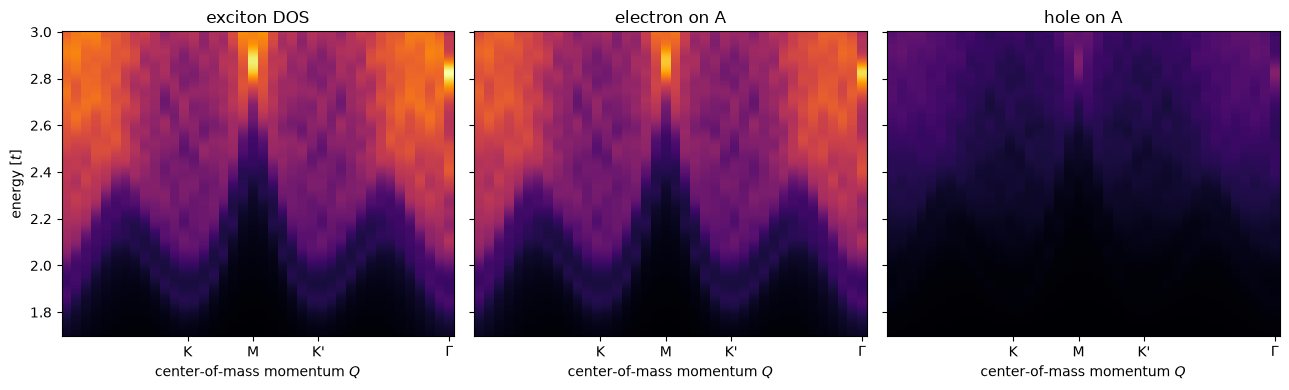

electron on A at 1.86t: 0.891
hole on A at 1.86t:     0.11


In [3]:
ws = np.linspace(1.7,3.0,300) # energy grid
opts = dict(V=W,nq=40,nk=18,energies=ws,delta=0.05)
qs,es,ds = h.get_exciton_kdos_bands(**opts) # exciton density of states
qs,es,de = h.get_exciton_kdos_bands(operator="sublatticeA",particle="electron",**opts)
qs,es,dh = h.get_exciton_kdos_bands(operator="sublatticeA",particle="hole",**opts)

nq = qs.max()+1
x = (np.arange(nq)+1)/nq # position along the path
D,DE,DH = [d.reshape(nq,-1).T for d in (ds,de,dh)] # (energy, q-point)

fig,ax = plt.subplots(1,3,figsize=(13,4),sharey=True)
for a,M,t in zip(ax,[D,DE,DH],["exciton DOS","electron on A","hole on A"]):
    a.pcolormesh(x,ws,np.sqrt(np.abs(M)),shading="nearest",cmap="inferno",
                 vmax=np.sqrt(D.max())) # square root, so the bound states are visible
    a.set_xticks([1/3,1/2,2/3,1],["K","M","K'","$\\Gamma$"])
    a.set_title(t) ; a.set_xlabel("center-of-mass momentum $Q$")
ax[0].set_ylabel("energy [$t$]")
plt.tight_layout() ; plt.show()

i = np.argmin(np.abs(ws-1.86)) # the bottom of the exciton band
print("electron on A at 1.86t:",np.round(np.mean(DE[i]/D[i]),3))
print("hole on A at 1.86t:    ",np.round(np.mean(DH[i]/D[i]),3))

The thin line below the continuum is the bound exciton band. It is lowest at $\Gamma$, has a
second minimum at K and K', and enters the continuum of free electron-hole pairs near M. The middle
panel is almost the whole map, and the right panel is almost empty: averaged over the path, the
electron at $1.86t$ sits on sublattice A with probability 0.89 and the hole with 0.11, so the hole
is on B, as the valence band it comes from. The projections on A and B add up to the total.

### The structure factor
The structure factor only shows the excitons that couple to a density fluctuation at momentum
$Q$. At $Q=0$ a uniform change of the density creates no electron-hole pair between two bands,
so $S$ goes to zero at $\Gamma$.

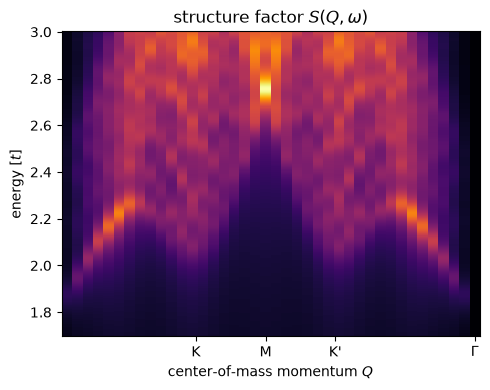

In [4]:
qs,es,ss = h.get_exciton_structure_factor(**opts)
S = ss.reshape(nq,-1).T
fig,ax = plt.subplots(figsize=(5,4))
ax.pcolormesh(x,ws,np.sqrt(S),shading="nearest",cmap="inferno")
ax.set_xticks([1/3,1/2,2/3,1],["K","M","K'","$\\Gamma$"])
ax.set_xlabel("center-of-mass momentum $Q$") ; ax.set_ylabel("energy [$t$]")
ax.set_title("structure factor $S(Q,\\omega)$")
plt.tight_layout() ; plt.show()

The bound exciton is the bright line that rises from $\Gamma$, with a weight that vanishes at
$\Gamma$ itself, and enters the continuum on the way to K. The bottom of the exciton band near K
and K' is dark here: the density fluctuation at that momentum hardly couples to it, so an EELS
experiment sees only part of the exciton bands that the density of states shows.